Imports e conexão

# FIAP Tech Challenge — Fase 3
### Análise Exploratória e Preparação dos Dados para Machine Learning

Este notebook prepara os dados construídos na Fase 2 para a etapa de modelagem supervisionada da Fase 3.

O processo contempla a seleção da população efetivamente avaliada, análise exploratória, prevenção de Data Leakage, enriquecimento com dados externos do IBGE e do Censo Escolar e construção de uma base Gold preparada para Machine Learning.

In [225]:
from pathlib import Path
from zipfile import ZipFile
import duckdb
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import requests

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
sns.set_theme(style="whitegrid")

PROJECT_ROOT = Path.cwd().parent
SILVER_ALUNOS = PROJECT_ROOT / "data" / "silver" / "alunos"
SILVER_MUNICIPIO = PROJECT_ROOT / "data" / "silver" / "municipio_integrado"
INEP_DIR = PROJECT_ROOT / "data" / "external" / "inep"
AREA_IBGE = PROJECT_ROOT / "data" / "external" / "ibge" / "AR_BR_RG_UF_RGINT_RGI_MUN_2025.xls"

con = duckdb.connect()

con.execute(f"""
CREATE OR REPLACE VIEW alunos AS
SELECT *
FROM read_parquet('{(SILVER_ALUNOS / "**" / "*.parquet").as_posix()}', hive_partitioning=true)
""")

con.execute(f"""
CREATE OR REPLACE VIEW municipio AS
SELECT *
FROM read_parquet('{(SILVER_MUNICIPIO / "**" / "*.parquet").as_posix()}', hive_partitioning=true)
""")

print("Projeto:", PROJECT_ROOT)
print("Base alunos:", SILVER_ALUNOS.exists())
print("Base município:", SILVER_MUNICIPIO.exists())

Projeto: c:\Users\caleb\OneDrive\Área de Trabalho\FIAP-Tech-Challenge-Alfabetizacao
Base alunos: True
Base município: True


### 1. Definição da população analisada

A base contém registros de alunos ausentes e alunos que não preencheram o caderno da avaliação.

Como esses registros não representam alunos efetivamente avaliados, a população principal considera apenas estudantes presentes e com o caderno preenchido.

Essa filtragem evita que ausências sejam interpretadas incorretamente como casos de não alfabetização.

Alunos avaliados

In [226]:
con.execute("""
CREATE OR REPLACE VIEW alunos_avaliados AS
SELECT *
FROM alunos
WHERE presenca_flag = 1
  AND preenchimento_caderno_flag = 1
""")

df_resumo = con.execute("""
SELECT
    ano,
    COUNT(*) AS qt_alunos_avaliados,
    SUM(alfabetizado_flag) AS qt_alfabetizados,
    ROUND(AVG(alfabetizado_flag) * 100, 2) AS tx_alfabetizacao
FROM alunos_avaliados
GROUP BY ano
ORDER BY ano
""").df()

display(df_resumo)
print("Total avaliado:", con.execute("SELECT COUNT(*) FROM alunos_avaliados").fetchone()[0])

,ano,qt_alunos_avaliados,qt_alfabetizados,tx_alfabetizacao
0,2023,1502809,"877,427.00",58.39
1,2024,1851852,"1,107,119.00",59.78


Total avaliado: 3354661


### 2. Análise exploratória dos dados

A análise exploratória busca identificar padrões iniciais relacionados à alfabetização.

Nesta etapa são avaliadas diferenças entre anos, Unidades da Federação e redes de ensino, permitindo observar desigualdades territoriais e educacionais presentes na base.

EDA resumida

,nm_uf,qt_alunos_avaliados,tx_alfabetizacao
0,CE,183707,85.01
1,PR,239191,72.22
2,ES,87379,70.19
3,GO,143667,69.97
4,MG,369007,66.62
5,RO,40143,64.14
6,SC,149691,63.12
7,PE,157101,60.09
8,DF,22111,59.43
9,SP,395444,58.56


,ano,rede,qt_alunos_avaliados,tx_alfabetizacao
0,2023,Estadual,131522,61.33
1,2023,Municipal,1371287,58.10
2,2024,Privada,24,66.67
3,2024,Estadual,241074,62.54
4,2024,Municipal,1610754,59.37


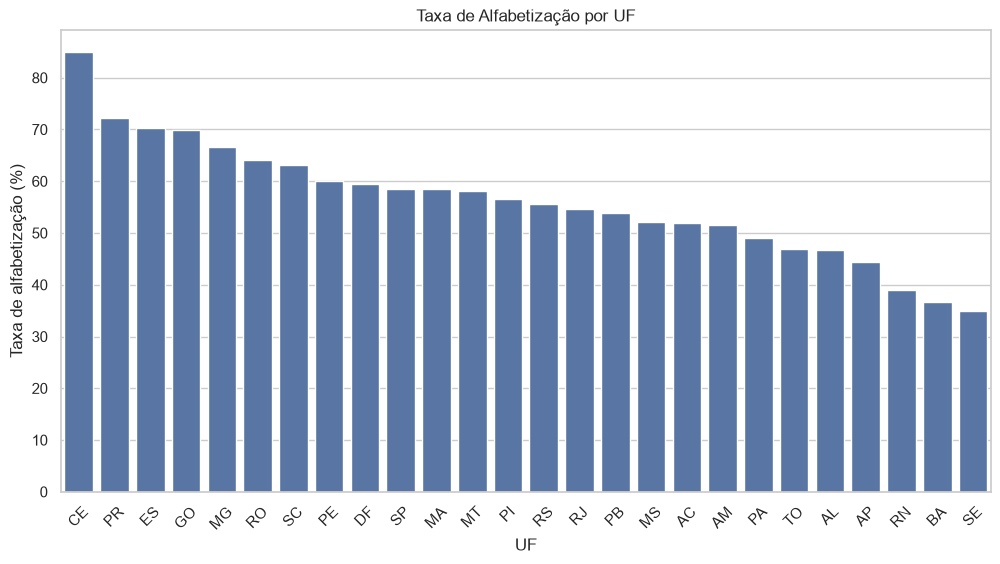

In [227]:
mapa_uf = {
    "11":"RO","12":"AC","13":"AM","14":"RR","15":"PA","16":"AP","17":"TO",
    "21":"MA","22":"PI","23":"CE","24":"RN","25":"PB","26":"PE","27":"AL","28":"SE","29":"BA",
    "31":"MG","32":"ES","33":"RJ","35":"SP",
    "41":"PR","42":"SC","43":"RS",
    "50":"MS","51":"MT","52":"GO","53":"DF"
}

df_uf = con.execute("""
SELECT
    codigo_uf,
    COUNT(*) AS qt_alunos_avaliados,
    ROUND(AVG(alfabetizado_flag) * 100, 2) AS tx_alfabetizacao
FROM alunos_avaliados
GROUP BY codigo_uf
ORDER BY tx_alfabetizacao DESC
""").df()

df_uf["nm_uf"] = df_uf["codigo_uf"].map(mapa_uf)

df_rede = con.execute("""
SELECT
    ano,
    rede,
    COUNT(*) AS qt_alunos_avaliados,
    ROUND(AVG(alfabetizado_flag) * 100, 2) AS tx_alfabetizacao
FROM alunos_avaliados
GROUP BY ano, rede
ORDER BY ano, tx_alfabetizacao DESC
""").df()

display(df_uf[["nm_uf","qt_alunos_avaliados","tx_alfabetizacao"]])
display(df_rede)

plt.figure(figsize=(12, 6))
sns.barplot(data=df_uf, x="nm_uf", y="tx_alfabetizacao")
plt.title("Taxa de Alfabetização por UF")
plt.xlabel("UF")
plt.ylabel("Taxa de alfabetização (%)")
plt.xticks(rotation=45)
plt.show()

### 4. Contexto educacional municipal

Os dados individuais são enriquecidos com indicadores municipais construídos na Fase 2.

São utilizados indicadores relacionados ao volume de alunos, presença e participação na avaliação.

Essas informações permitem representar parte do contexto educacional do município sem utilizar diretamente indicadores derivados da alfabetização.

Contexto municipal da Fase 2

In [228]:
con.execute("""
CREATE OR REPLACE VIEW alunos_contexto_municipal AS
SELECT
    a.*,
    m.total_alunos AS total_alunos_municipio,
    m.alunos_presentes AS alunos_presentes_municipio,
    m.taxa_presenca AS taxa_presenca_municipio,
    m.percentual_participacao AS percentual_participacao_municipio
FROM alunos_avaliados a
LEFT JOIN municipio m
    ON a.ano = m.ano
   AND a.id_municipio = m.id_municipio
   AND a.rede_codigo = m.rede_codigo
""")

display(
    con.execute("""
    SELECT
        COUNT(*) AS qt_registros,
        SUM(CASE WHEN taxa_presenca_municipio IS NULL THEN 1 ELSE 0 END) AS qt_sem_contexto
    FROM alunos_contexto_municipal
    """).df()
)

,qt_registros,qt_sem_contexto
0,3354661,190.00


### 5. Enriquecimento socioeconômico — IBGE

A base é enriquecida com dados externos do IBGE para incorporar características demográficas e econômicas dos municípios.

São adicionadas informações de população, área territorial, densidade demográfica, Produto Interno Bruto municipal e PIB per capita aproximado.

Essas variáveis ajudam a representar diferenças estruturais entre os municípios analisados.

IBGE: municípios, população e PIB

In [229]:
url_municipios = "https://servicodados.ibge.gov.br/api/v1/localidades/municipios"
dados_municipios = requests.get(url_municipios).json()

df_municipios = pd.DataFrame([
    {"id_municipio": str(item["id"]), "nm_municipio": item["nome"]}
    for item in dados_municipios
])

url_populacao = (
    "https://servicodados.ibge.gov.br/api/v3/agregados/"
    "6579/periodos/2024/variaveis/9324?localidades=N6[all]"
)

dados_populacao = requests.get(url_populacao).json()
serie_populacao = dados_populacao[0]["resultados"][0]["series"]

df_populacao = pd.DataFrame([
    {
        "id_municipio": str(item["localidade"]["id"]),
        "qt_populacao_2024": int(item["serie"]["2024"])
    }
    for item in serie_populacao
    if item["serie"]["2024"] not in ("-", "...", None)
])

url_pib = "https://apisidra.ibge.gov.br/values/t/5938/n6/all/v/37/p/2023"
dados_pib = requests.get(url_pib).json()

df_pib = pd.DataFrame(dados_pib[1:])[["D1C", "V"]]
df_pib.columns = ["id_municipio", "vl_pib_municipio_mil_reais"]
df_pib["id_municipio"] = df_pib["id_municipio"].astype(str)
df_pib["vl_pib_municipio_mil_reais"] = pd.to_numeric(df_pib["vl_pib_municipio_mil_reais"], errors="coerce")

df_ibge = (
    df_municipios
    .merge(df_populacao, on="id_municipio", how="left")
    .merge(df_pib, on="id_municipio", how="left")
)

df_ibge["vl_pib_per_capita_aprox"] = (
    df_ibge["vl_pib_municipio_mil_reais"] * 1000
    / df_ibge["qt_populacao_2024"]
)

### 6. Área territorial e densidade demográfica

A área territorial dos municípios é utilizada em conjunto com a população para calcular a densidade demográfica.

Esse indicador permite diferenciar municípios com populações semelhantes, mas características territoriais distintas, contribuindo para uma representação mais completa do contexto municipal.

Área territorial e densidade demográfica

In [230]:
df_area = pd.read_excel(AREA_IBGE)

df_area = df_area[[
    "CD_MUN",
    "AR_MUN_2025"
]].copy()

df_area.columns = [
    "id_municipio",
    "vl_area_municipio_km2"
]

df_area["id_municipio"] = (
    df_area["id_municipio"]
    .astype(str)
    .str.replace(".0", "", regex=False)
    .str.strip()
    .str.zfill(7)
)

df_area["vl_area_municipio_km2"] = pd.to_numeric(
    df_area["vl_area_municipio_km2"],
    errors="coerce"
)

df_area = df_area.dropna(
    subset=[
        "id_municipio",
        "vl_area_municipio_km2"
    ]
)

df_area = df_area.drop_duplicates(
    subset=["id_municipio"]
)

df_ibge = df_ibge.merge(
    df_area,
    on="id_municipio",
    how="left"
)

df_ibge["nr_densidade_demografica"] = (
    df_ibge["qt_populacao_2024"]
    / df_ibge["vl_area_municipio_km2"]
)

display(
    df_ibge[
        [
            "id_municipio",
            "nm_municipio",
            "qt_populacao_2024",
            "vl_area_municipio_km2",
            "nr_densidade_demografica"
        ]
    ].head()
)

print(
    "Municípios sem área:",
    df_ibge["vl_area_municipio_km2"].isna().sum()
)

,id_municipio,nm_municipio,qt_populacao_2024,vl_area_municipio_km2,nr_densidade_demografica
0,1100015,Alta Floresta D'Oeste,"22,853.00","7,067.13",3.23
1,1100023,Ariquemes,"108,573.00","4,426.13",24.53
2,1100031,Cabixi,"5,690.00","1,314.35",4.33
3,1100049,Cacoal,"97,637.00","3,793.00",25.74
4,1100056,Cerejeiras,"16,975.00","2,783.30",6.10


Municípios sem área: 0


### 7. Enriquecimento com Censo Escolar

Os microdados do Censo Escolar de 2023 e 2024 são utilizados para adicionar informações relacionadas à estrutura da rede educacional.

Como os identificadores de escola presentes na base da Fase 2 são anonimizados, a integração é realizada de forma agregada por ano, município e rede de ensino.

São incorporadas informações sobre quantidade de escolas, matrículas, docentes, salas utilizadas, localização rural ou urbana e disponibilidade de infraestrutura escolar.

Extrair Censo Escolar e localizar CSV

In [231]:
def extrair_censo(ano):
    arquivo_zip = INEP_DIR / str(ano) / f"microdados_censo_escolar_{ano}.zip"
    pasta_saida = INEP_DIR / str(ano) / "extraido"
    pasta_saida.mkdir(parents=True, exist_ok=True)
    with ZipFile(arquivo_zip, "r") as zip_ref:
        zip_ref.extractall(pasta_saida)
    return pasta_saida

PASTA_CENSO_2023 = extrair_censo(2023)
PASTA_CENSO_2024 = extrair_censo(2024)

print("2023:", PASTA_CENSO_2023)
print("2024:", PASTA_CENSO_2024)

def localizar_csv_censo(pasta):
    arquivos_csv = list(pasta.rglob("*.csv"))
    if not arquivos_csv:
        raise FileNotFoundError(f"Nenhum CSV encontrado em {pasta}")
    candidatos = [
        arquivo
        for arquivo in arquivos_csv
        if "microdados" in arquivo.name.lower() and "ed_basica" in arquivo.name.lower()
    ]
    if candidatos:
        return candidatos[0]
    return max(arquivos_csv, key=lambda x: x.stat().st_size)

ARQ_CENSO_2023 = localizar_csv_censo(PASTA_CENSO_2023)
ARQ_CENSO_2024 = localizar_csv_censo(PASTA_CENSO_2024)

print("CSV 2023:", ARQ_CENSO_2023)
print("CSV 2024:", ARQ_CENSO_2024)

2023: c:\Users\caleb\OneDrive\Área de Trabalho\FIAP-Tech-Challenge-Alfabetizacao\data\external\inep\2023\extraido
2024: c:\Users\caleb\OneDrive\Área de Trabalho\FIAP-Tech-Challenge-Alfabetizacao\data\external\inep\2024\extraido
CSV 2023: c:\Users\caleb\OneDrive\Área de Trabalho\FIAP-Tech-Challenge-Alfabetizacao\data\external\inep\2023\extraido\microdados_censo_escolar_2023\dados\microdados_ed_basica_2023.csv
CSV 2024: c:\Users\caleb\OneDrive\Área de Trabalho\FIAP-Tech-Challenge-Alfabetizacao\data\external\inep\2024\extraido\microdados_censo_escolar_2024_defeso\dados\microdados_ed_basica_2024.csv


Carregar Censo Escolar

In [232]:
COLUNAS_CENSO = [
    "CO_ENTIDADE",
    "CO_MUNICIPIO",
    "TP_LOCALIZACAO",
    "TP_DEPENDENCIA",
    "QT_MAT_BAS",
    "QT_DOC_BAS",
    "QT_SALAS_UTILIZADAS",
    "IN_INTERNET",
    "IN_BIBLIOTECA",
    "IN_SALA_LEITURA",
    "IN_LABORATORIO_INFORMATICA",
    "IN_QUADRA_ESPORTES",
    "IN_AGUA_POTAVEL",
    "IN_ENERGIA_REDE_PUBLICA"
]

def carregar_censo(caminho, ano):
    try:
        cabecalho = pd.read_csv(caminho, sep=";", encoding="utf-8", nrows=0)
        encoding = "utf-8"
    except UnicodeDecodeError:
        cabecalho = pd.read_csv(caminho, sep=";", encoding="latin1", nrows=0)
        encoding = "latin1"

    colunas_disponiveis = [
        coluna for coluna in COLUNAS_CENSO
        if coluna in cabecalho.columns
    ]

    df = pd.read_csv(
        caminho,
        sep=";",
        encoding=encoding,
        usecols=colunas_disponiveis,
        low_memory=False
    )

    df["nr_ano"] = ano
    return df

df_censo_2023 = carregar_censo(ARQ_CENSO_2023, 2023)
df_censo_2024 = carregar_censo(ARQ_CENSO_2024, 2024)

df_censo = pd.concat(
    [df_censo_2023, df_censo_2024],
    ignore_index=True
)

print("Registros Censo:", len(df_censo))

Registros Censo: 433170


Agregação do Censo

In [233]:
df_censo["id_municipio"] = (
    df_censo["CO_MUNICIPIO"]
    .astype(str)
    .str.replace(".0", "", regex=False)
    .str.zfill(7)
)

df_censo["rede_codigo"] = pd.to_numeric(df_censo["TP_DEPENDENCIA"], errors="coerce")

df_censo_ativo = df_censo[
    pd.to_numeric(df_censo["QT_MAT_BAS"], errors="coerce").fillna(0) > 0
].copy()

df_censo_ativo["fl_biblioteca_ou_sala_leitura"] = (
    df_censo_ativo[["IN_BIBLIOTECA", "IN_SALA_LEITURA"]].max(axis=1)
)

df_censo_ativo["fl_escola_rural"] = (
    df_censo_ativo["TP_LOCALIZACAO"] == 2
).astype(int)

df_censo_municipio = (
    df_censo_ativo
    .groupby(["nr_ano", "id_municipio", "rede_codigo"], as_index=False)
    .agg(
        qt_escolas_censo=("CO_ENTIDADE", "nunique"),
        qt_matriculas_censo=("QT_MAT_BAS", "sum"),
        qt_docentes_censo=("QT_DOC_BAS", "sum"),
        qt_salas_utilizadas_censo=("QT_SALAS_UTILIZADAS", "sum"),
        tx_escolas_rurais=("fl_escola_rural", "mean"),
        tx_escolas_internet=("IN_INTERNET", "mean"),
        tx_escolas_biblioteca_sala_leitura=("fl_biblioteca_ou_sala_leitura", "mean"),
        tx_escolas_lab_informatica=("IN_LABORATORIO_INFORMATICA", "mean"),
        tx_escolas_quadra=("IN_QUADRA_ESPORTES", "mean"),
        tx_escolas_agua_potavel=("IN_AGUA_POTAVEL", "mean"),
        tx_escolas_energia_rede_publica=("IN_ENERGIA_REDE_PUBLICA", "mean")
    )
)

colunas_taxas = [
    "tx_escolas_rurais",
    "tx_escolas_internet",
    "tx_escolas_biblioteca_sala_leitura",
    "tx_escolas_lab_informatica",
    "tx_escolas_quadra",
    "tx_escolas_agua_potavel",
    "tx_escolas_energia_rede_publica"
]

df_censo_municipio[colunas_taxas] *= 100

df_censo_municipio["tx_escolas_urbanas"] = (
    100 - df_censo_municipio["tx_escolas_rurais"]
)

df_censo_municipio["nr_alunos_por_docente"] = (
    df_censo_municipio["qt_matriculas_censo"]
    / df_censo_municipio["qt_docentes_censo"].replace(0, pd.NA)
)

df_censo_municipio["nr_matriculas_por_escola"] = (
    df_censo_municipio["qt_matriculas_censo"]
    / df_censo_municipio["qt_escolas_censo"]
)

df_censo_municipio["nr_salas_por_escola"] = (
    df_censo_municipio["qt_salas_utilizadas_censo"]
    / df_censo_municipio["qt_escolas_censo"]
)

display(df_censo_municipio.head())

print(
    "Duplicidades:",
    df_censo_municipio.duplicated(
        ["nr_ano", "id_municipio", "rede_codigo"]
    ).sum()
)

,nr_ano,id_municipio,rede_codigo,qt_escolas_censo,qt_matriculas_censo,qt_docentes_censo,qt_salas_utilizadas_censo,tx_escolas_rurais,tx_escolas_internet,tx_escolas_biblioteca_sala_leitura,tx_escolas_lab_informatica,tx_escolas_quadra,tx_escolas_agua_potavel,tx_escolas_energia_rede_publica,tx_escolas_urbanas,nr_alunos_por_docente,nr_matriculas_por_escola,nr_salas_por_escola
0,2023,1100015,2,12,"2,337.00",204.00,103.00,58.33,66.67,41.67,41.67,41.67,100.00,58.33,41.67,11.46,194.75,8.58
1,2023,1100015,3,14,"2,648.00",190.00,111.00,28.57,100.00,42.86,0.00,71.43,100.00,100.00,71.43,13.94,189.14,7.93
2,2023,1100023,1,1,538.00,56.00,23.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00,0.00,9.61,538.00,23.00
3,2023,1100023,2,11,"8,783.00",330.00,208.00,9.09,100.00,100.00,90.91,90.91,100.00,100.00,90.91,26.62,798.45,18.91
4,2023,1100023,3,27,"10,181.00",428.00,282.00,25.93,100.00,62.96,85.19,55.56,96.30,100.00,74.07,23.79,377.07,10.44


Duplicidades: 0


### 8. Integração das fontes de dados

Após o tratamento das fontes externas, os dados dos alunos são integrados aos indicadores municipais do projeto, aos dados socioeconômicos do IBGE e às características estruturais do Censo Escolar.

A integração preserva a granularidade individual dos alunos, enquanto adiciona informações contextuais do município e da rede de ensino.

Base enriquecida

In [234]:
con.register("ibge", df_ibge)
con.register("censo_municipio", df_censo_municipio)

con.execute("""
CREATE OR REPLACE VIEW base_enriquecida AS
SELECT
    a.ano,
    a.id_municipio,
    a.id_escola,
    a.id_aluno,
    a.codigo_uf,
    a.rede_codigo,
    a.rede,
    a.alfabetizado_flag,
    m.total_alunos AS total_alunos_municipio,
    m.alunos_presentes AS alunos_presentes_municipio,
    m.taxa_presenca AS taxa_presenca_municipio,
    m.percentual_participacao AS percentual_participacao_municipio,
    i.nm_municipio,
    i.qt_populacao_2024,
    i.vl_area_municipio_km2,
    i.nr_densidade_demografica,
    i.vl_pib_municipio_mil_reais,
    i.vl_pib_per_capita_aprox,
    c.qt_escolas_censo,
    c.qt_matriculas_censo,
    c.qt_docentes_censo,
    c.qt_salas_utilizadas_censo,
    c.nr_alunos_por_docente,
    c.nr_matriculas_por_escola,
    c.nr_salas_por_escola,
    c.tx_escolas_rurais,
    c.tx_escolas_urbanas,
    c.tx_escolas_internet,
    c.tx_escolas_biblioteca_sala_leitura,
    c.tx_escolas_lab_informatica,
    c.tx_escolas_quadra,
    c.tx_escolas_agua_potavel,
    c.tx_escolas_energia_rede_publica
FROM alunos_avaliados a
LEFT JOIN municipio m
    ON a.ano = m.ano
   AND a.id_municipio = m.id_municipio
   AND a.rede_codigo = m.rede_codigo
LEFT JOIN ibge i
    ON a.id_municipio = i.id_municipio
LEFT JOIN censo_municipio c
    ON a.ano = c.nr_ano
   AND a.id_municipio = c.id_municipio
   AND a.rede_codigo = c.rede_codigo
""")

### 9. Construção da base final para Machine Learning

A base final reúne as variáveis selecionadas para a etapa de modelagem.

Os campos seguem uma taxonomia padronizada:

- `id_`: identificadores;
- `cd_`: códigos;
- `nm_`: nomes e categorias;
- `qt_`: quantidades;
- `tx_`: taxas e percentuais;
- `vl_`: valores;
- `nr_`: indicadores numéricos;
- `dt_`: indicadores de data;
- `fl_`: flags.

Os identificadores são mantidos para rastreabilidade, mas não devem ser utilizados diretamente como variáveis preditoras.

A variável alvo do modelo é `fl_alfabetizado`.

Base final para ML

In [235]:
con.execute("""
CREATE OR REPLACE VIEW base_modelagem AS
SELECT
    id_aluno,
    id_escola,
    id_municipio,
    ano AS dt_ano,
    codigo_uf AS cd_uf,
    CASE
        WHEN codigo_uf IN ('11','12','13','14','15','16','17') THEN 'Norte'
        WHEN codigo_uf IN ('21','22','23','24','25','26','27','28','29') THEN 'Nordeste'
        WHEN codigo_uf IN ('31','32','33','35') THEN 'Sudeste'
        WHEN codigo_uf IN ('41','42','43') THEN 'Sul'
        WHEN codigo_uf IN ('50','51','52','53') THEN 'Centro-Oeste'
    END AS nm_regiao,
    nm_municipio,
    rede_codigo AS cd_rede,
    rede AS nm_rede,
    total_alunos_municipio AS qt_alunos_municipio,
    alunos_presentes_municipio AS qt_alunos_presentes_municipio,
    taxa_presenca_municipio AS tx_presenca_municipio,
    percentual_participacao_municipio AS tx_participacao_municipio,
    qt_escolas_censo,
    qt_matriculas_censo,
    qt_docentes_censo,
    qt_salas_utilizadas_censo,
    nr_alunos_por_docente,
    nr_matriculas_por_escola,
    nr_salas_por_escola,
    tx_escolas_rurais,
    tx_escolas_urbanas,
    tx_escolas_internet,
    tx_escolas_biblioteca_sala_leitura,
    tx_escolas_lab_informatica,
    tx_escolas_quadra,
    tx_escolas_agua_potavel,
    tx_escolas_energia_rede_publica,
    qt_populacao_2024 AS qt_populacao_municipio,
    vl_area_municipio_km2,
    nr_densidade_demografica,
    vl_pib_municipio_mil_reais,
    vl_pib_per_capita_aprox,
    alfabetizado_flag AS fl_alfabetizado
FROM base_enriquecida
""")

### 10. Conclusão

A etapa de preparação resultou em uma base Gold enriquecida e estruturada para Machine Learning.

A base combina informações de diferentes dimensões:

- características territoriais;
- rede de ensino;
- participação educacional;
- estrutura das escolas;
- ruralidade e urbanização;
- infraestrutura escolar;
- população;
- área territorial;
- densidade demográfica;
- atividade econômica municipal.

Variáveis diretamente relacionadas à definição do alvo, principalmente a proficiência, foram excluídas da base de modelagem para evitar Data Leakage.

O arquivo `base_modelagem.parquet` representa a entrada preparada para a próxima etapa do projeto, que envolverá preprocessing, divisão entre treino e teste, treinamento, avaliação e interpretação dos modelos.

Exportação da Gold

In [236]:
OUTPUT_DIR = PROJECT_ROOT / "data" / "gold" / "fase3"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

OUTPUT_FILE = OUTPUT_DIR / "base_modelagem.parquet"

con.execute(f"""
COPY (
    SELECT *
    FROM base_modelagem
)
TO '{OUTPUT_FILE.as_posix()}'
(FORMAT PARQUET, COMPRESSION SNAPPY)
""")

print("Base salva em:", OUTPUT_FILE)

Base salva em: c:\Users\caleb\OneDrive\Área de Trabalho\FIAP-Tech-Challenge-Alfabetizacao\data\gold\fase3\base_modelagem.parquet


In [237]:
PARQUET_FINAL = PROJECT_ROOT / "data" / "gold" / "fase3" / "base_modelagem.parquet"

display(
    con.execute(f"""
    SELECT *
    FROM read_parquet('{PARQUET_FINAL.as_posix()}')
    LIMIT 20
    """).df()
)

,id_aluno,id_escola,id_municipio,dt_ano,cd_uf,nm_regiao,nm_municipio,cd_rede,nm_rede,qt_alunos_municipio,qt_alunos_presentes_municipio,tx_presenca_municipio,tx_participacao_municipio,qt_escolas_censo,qt_matriculas_censo,qt_docentes_censo,qt_salas_utilizadas_censo,nr_alunos_por_docente,nr_matriculas_por_escola,nr_salas_por_escola,tx_escolas_rurais,tx_escolas_urbanas,tx_escolas_internet,tx_escolas_biblioteca_sala_leitura,tx_escolas_lab_informatica,tx_escolas_quadra,tx_escolas_agua_potavel,tx_escolas_energia_rede_publica,qt_populacao_municipio,vl_area_municipio_km2,nr_densidade_demografica,vl_pib_municipio_mil_reais,vl_pib_per_capita_aprox,fl_alfabetizado
0,31146570,60021136,3168606,2023,31,Sudeste,Teófilo Otoni,3,Municipal,672,593,88.24,88.24,59,"9,375.00",602.00,401.00,15.57,158.90,6.80,44.07,55.93,54.24,22.03,0.00,16.95,66.10,100.00,"142,571.00","3,242.27",43.97,"3,540,248.00","24,831.47",1
1,43030225,60036976,4302105,2023,43,Sul,Bento Gonçalves,3,Municipal,895,766,85.59,85.59,46,"10,624.00",705.00,358.00,15.07,230.96,7.78,2.17,97.83,100.00,54.35,36.96,41.30,100.00,100.00,"127,775.00",272.22,469.39,"9,062,598.00","70,926.22",1
2,52062354,60042298,5213103,2023,52,Centro-Oeste,Mineiros,3,Municipal,1082,970,89.65,89.65,32,"8,158.00",410.00,225.00,19.90,254.94,7.03,28.12,71.88,100.00,43.75,28.12,34.38,100.00,100.00,"73,781.00","9,042.84",8.16,"4,536,325.00","61,483.65",1
3,43039245,60038921,4317103,2023,43,Sul,Sant'Ana do Livramento,2,Estadual,652,525,80.52,NaN,25,"8,140.00",534.00,283.00,15.24,325.60,11.32,24.00,76.00,92.00,72.00,60.00,36.00,100.00,100.00,"87,296.00","6,946.41",12.57,"3,143,614.00","36,010.97",0
4,33103707,60025880,3304557,2023,33,Sudeste,Rio de Janeiro,3,Municipal,54533,44858,82.26,82.26,1550,"615,038.00","27,881.00","16,690.00",22.06,396.80,10.77,0.00,100.00,98.97,84.39,40.52,50.71,100.00,100.00,"6,729,894.00","1,200.33","5,606.71","418,462,360.00","62,179.64",0
5,29031717,60018045,2931350,2023,29,Nordeste,Teixeira de Freitas,3,Municipal,1625,1370,84.31,84.31,72,"20,341.00","1,083.00",549.00,18.78,282.51,7.62,23.61,76.39,86.11,44.44,1.39,29.17,81.94,94.44,"153,332.00","1,165.62",131.55,"3,670,771.00","23,940.02",1
6,31110750,60022190,3170206,2023,31,Sudeste,Uberlândia,3,Municipal,5777,4879,84.46,84.46,121,"60,912.00","3,892.00","1,460.00",15.65,503.40,12.07,9.92,90.08,100.00,76.86,35.54,47.93,100.00,100.00,"754,954.00","4,115.21",183.45,"51,065,684.00","67,640.79",0
7,31190309,60018743,3151909,2023,31,Sudeste,Pocrane,2,Estadual,55,52,94.55,NaN,4,"1,024.00",81.00,28.00,12.64,256.00,7.00,25.00,75.00,100.00,50.00,100.00,50.00,100.00,100.00,"8,468.00",691.07,12.25,"151,974.00","17,946.86",0
8,33149762,60023794,3305406,2023,33,Sudeste,Sapucaia,3,Municipal,199,177,88.94,88.94,16,"2,482.00",218.00,103.00,11.39,155.12,6.44,37.50,62.50,100.00,31.25,12.50,18.75,100.00,100.00,"18,289.00",540.67,33.83,"1,227,721.00","67,128.93",0
9,31036370,60021528,3105301,2023,31,Sudeste,Bandeira do Sul,3,Municipal,88,86,97.73,97.73,2,756.00,65.00,36.00,11.63,378.00,18.00,0.00,100.00,100.00,50.00,50.00,50.00,100.00,100.00,"6,146.00",47.27,130.03,"113,862.00","18,526.20",0


In [239]:
display(
    con.execute(f"""
    SELECT *
    FROM read_parquet('{PARQUET_FINAL.as_posix()}')
    LIMIT 5
    """).df()
)

,id_aluno,id_escola,id_municipio,dt_ano,cd_uf,nm_regiao,nm_municipio,cd_rede,nm_rede,qt_alunos_municipio,qt_alunos_presentes_municipio,tx_presenca_municipio,tx_participacao_municipio,qt_escolas_censo,qt_matriculas_censo,qt_docentes_censo,qt_salas_utilizadas_censo,nr_alunos_por_docente,nr_matriculas_por_escola,nr_salas_por_escola,tx_escolas_rurais,tx_escolas_urbanas,tx_escolas_internet,tx_escolas_biblioteca_sala_leitura,tx_escolas_lab_informatica,tx_escolas_quadra,tx_escolas_agua_potavel,tx_escolas_energia_rede_publica,qt_populacao_municipio,vl_area_municipio_km2,nr_densidade_demografica,vl_pib_municipio_mil_reais,vl_pib_per_capita_aprox,fl_alfabetizado
0,31146570,60021136,3168606,2023,31,Sudeste,Teófilo Otoni,3,Municipal,672,593,88.24,88.24,59,"9,375.00",602.00,401.00,15.57,158.90,6.80,44.07,55.93,54.24,22.03,0.00,16.95,66.10,100.00,"142,571.00","3,242.27",43.97,"3,540,248.00","24,831.47",1
1,43030225,60036976,4302105,2023,43,Sul,Bento Gonçalves,3,Municipal,895,766,85.59,85.59,46,"10,624.00",705.00,358.00,15.07,230.96,7.78,2.17,97.83,100.00,54.35,36.96,41.30,100.00,100.00,"127,775.00",272.22,469.39,"9,062,598.00","70,926.22",1
2,52062354,60042298,5213103,2023,52,Centro-Oeste,Mineiros,3,Municipal,1082,970,89.65,89.65,32,"8,158.00",410.00,225.00,19.90,254.94,7.03,28.12,71.88,100.00,43.75,28.12,34.38,100.00,100.00,"73,781.00","9,042.84",8.16,"4,536,325.00","61,483.65",1
3,43039245,60038921,4317103,2023,43,Sul,Sant'Ana do Livramento,2,Estadual,652,525,80.52,NaN,25,"8,140.00",534.00,283.00,15.24,325.60,11.32,24.00,76.00,92.00,72.00,60.00,36.00,100.00,100.00,"87,296.00","6,946.41",12.57,"3,143,614.00","36,010.97",0
4,33103707,60025880,3304557,2023,33,Sudeste,Rio de Janeiro,3,Municipal,54533,44858,82.26,82.26,1550,"615,038.00","27,881.00","16,690.00",22.06,396.80,10.77,0.00,100.00,98.97,84.39,40.52,50.71,100.00,100.00,"6,729,894.00","1,200.33","5,606.71","418,462,360.00","62,179.64",0
